# SizePath observational impact and decision analysis

> **Fictional, synthetic case study.** No real people, customers, or company data are used.

**Decision:** Should Riderly Bikes promote the fictional SizePath recommendation journey more aggressively?

**Primary observational estimand:** among eligible product-view sessions, the adjusted purchase-conversion difference associated with *starting* SizePath versus not starting it. Starting is self-selected; it is not randomized.

Success means reproducing the full 450,000-session result, checking overlap and observable balance, comparing naive/IPW/doubly-robust estimates with the generator's structural truth, and converting the limitation into a randomized-test recommendation.

In [1]:
from __future__ import annotations

import os
import sys
from pathlib import Path
from types import SimpleNamespace

import pandas as pd
from IPython.display import Image, display
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "analyses":
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

from analyses.run_sizepath import run  # noqa: E402

PROJECT_ID = "tracegate-r7m5o9ld"
CACHE = Path("artifacts/analysis/sizepath.parquet")
RESULTS = Path("analyses/results")
SEED = 3602026
{"project_id": PROJECT_ID, "cache_exists": CACHE.exists(), "seed": SEED}

{'project_id': 'tracegate-r7m5o9ld', 'cache_exists': True, 'seed': 3602026}

## Identification plan

The analysis uses only context known before a SizePath start: market, device, channel, viewed SKU, session hour/day/month, prior-session count, and prior-purchaser status. It deliberately excludes recommendation, cart, checkout, selected product, and all latent generator variables.

```text
Observed context ------> SizePath start ------> Purchase
          |                                      ^
          +--------------------------------------+
Latent intent --------> SizePath start
          |                                      ^
          +--------------------------------------+
```

Because latent intent affects both start and purchase, exchangeability is intentionally violated. Observable adjustment can improve balance but cannot guarantee an unbiased causal effect. The generator's structural truth is used only for validation and never appears in warehouse marts.

## Execute reproducibly

The first run needs Application Default Credentials that can query the Rider-prefixed BigQuery datasets. It writes an ignored Parquet cache; later runs use that immutable extract. Three user-grouped folds prevent one anonymous user's sessions leaking across training and validation folds.

In [2]:
result = run(
    SimpleNamespace(
        project_id=PROJECT_ID,
        cache=CACHE,
        results_dir=RESULTS,
        folds=3,
        refresh=False,
    )
)
{
    "sessions": result["sessions"],
    "anonymous_users": result["users"],
    "sizepath_start_rate": result["treatment_share"],
    "purchase_conversion": result["outcome_share"],
}

{'sessions': 450000,
 'anonymous_users': 355295,
 'sizepath_start_rate': 0.33964222222222223,
 'purchase_conversion': 0.059033333333333333}

## Overlap and balance

Propensity overlap is strong. A maximum absolute standardized mean difference below 0.10 is the conventional diagnostic target; this dataset is already well below it because the strongest confounder is intentionally unobserved. Good observable balance does **not** prove causal identification.

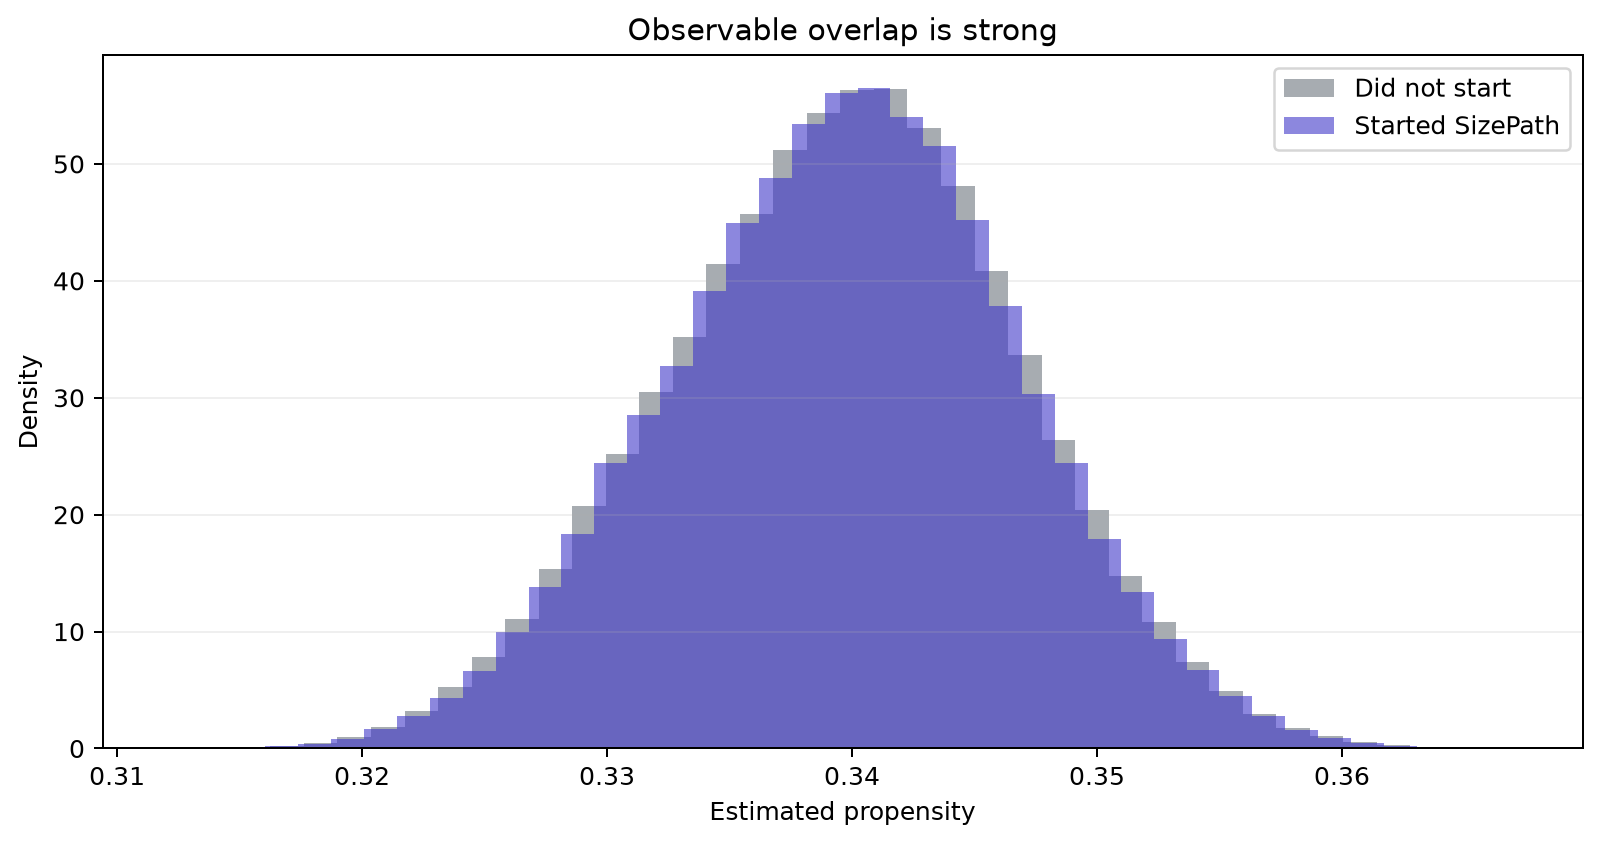

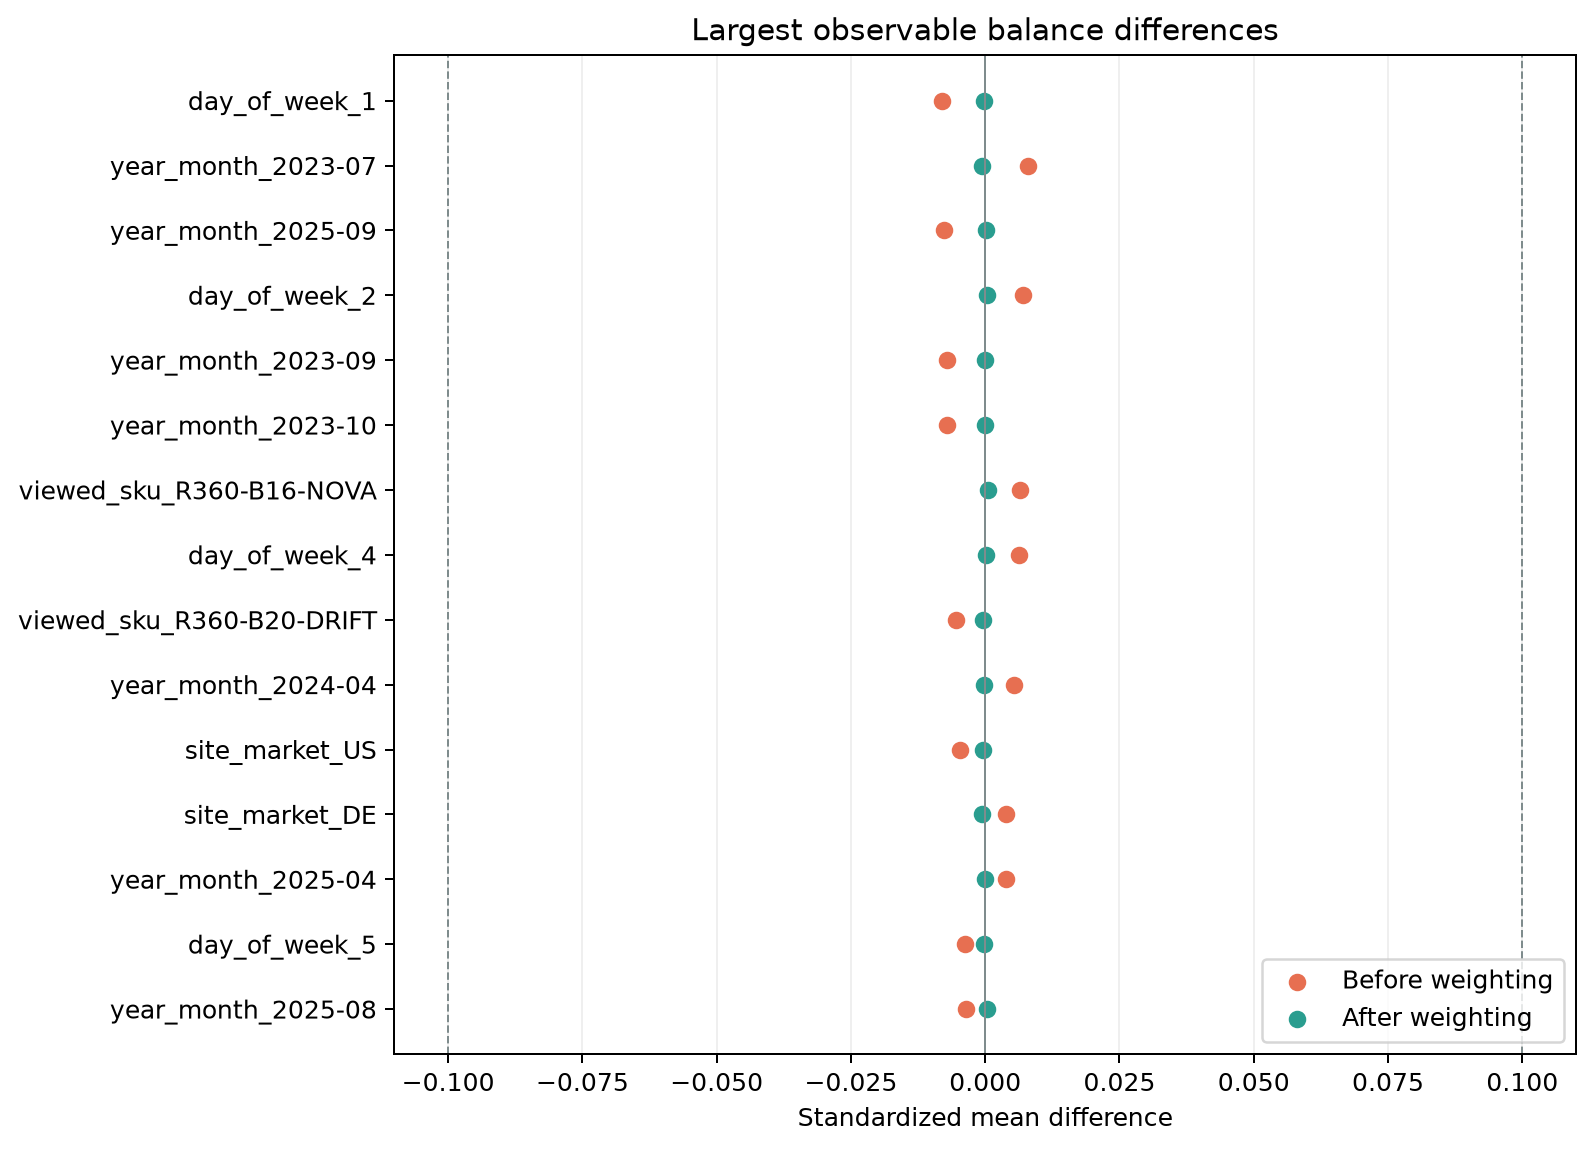

,diagnostic,value
0,propensity p01,0.323227
1,propensity p99,0.355783
2,max |SMD| before,0.008120
3,max |SMD| after,0.001105


In [3]:
display(Image(filename=str(RESULTS / "sizepath_overlap.png"), width=850))
display(Image(filename=str(RESULTS / "sizepath_balance.png"), width=850))
pd.DataFrame(
    {
        "diagnostic": ["propensity p01", "propensity p99", "max |SMD| before", "max |SMD| after"],
        "value": [
            result["propensity"]["p01"],
            result["propensity"]["p99"],
            result["maximum_absolute_smd_before"],
            result["maximum_absolute_smd_after"],
        ],
    }
)

## Effect estimates and synthetic truth

The naive contrast, stabilized inverse-probability weighting, and cross-fitted doubly robust estimator all use purchase risk difference as the effect scale. Confidence intervals use user-clustered influence functions. The dashed reference is the generator's integrated structural effect for the observed market/device/date mix.

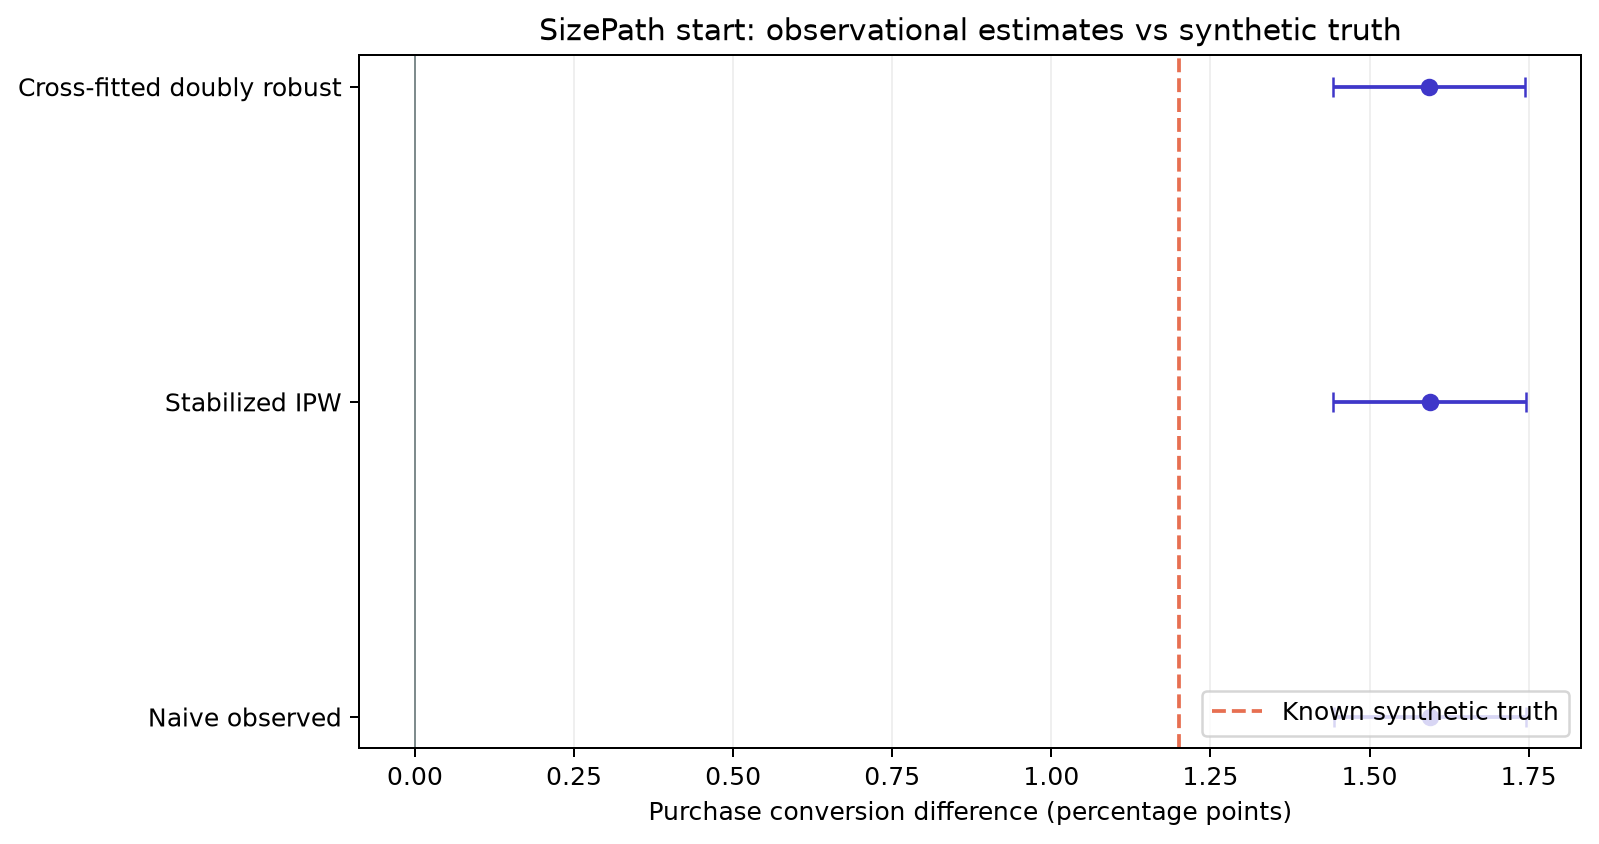

,method,estimate_pp,ci_low_pp,ci_high_pp
0,Naive observed,1.595,1.444,1.746
1,Stabilized IPW,1.594,1.443,1.745
2,Cross-fitted doubly robust,1.593,1.442,1.745


In [4]:
effects = pd.DataFrame(result["effects"])
display(Image(filename=str(RESULTS / "sizepath_effects.png"), width=850))
effects.assign(
    estimate_pp=lambda data: 100 * data["risk_difference"],
    ci_low_pp=lambda data: 100 * data["confidence_low"],
    ci_high_pp=lambda data: 100 * data["confidence_high"],
)[["method", "estimate_pp", "ci_low_pp", "ci_high_pp"]].round(3)

In [5]:
truth_pp = 100 * result["synthetic_truth"]["average_purchase_risk_difference"]
dr_pp = (
    100 * effects.loc[effects["method"] == "Cross-fitted doubly robust", "risk_difference"].iloc[0]
)
bias_pp = dr_pp - truth_pp
{
    "known_truth_pp": round(truth_pp, 3),
    "doubly_robust_estimate_pp": round(dr_pp, 3),
    "residual_bias_pp": round(bias_pp, 3),
    "structural_odds_ratio": round(result["synthetic_truth"]["conversion_odds_ratio"], 3),
}

{'known_truth_pp': 1.2,
 'doubly_robust_estimate_pp': np.float64(1.593),
 'residual_bias_pp': np.float64(0.393),
 'structural_odds_ratio': 1.271}

## Interpretation

SizePath starters convert about **1.59 percentage points** more often after observable adjustment (95% CI approximately 1.44–1.74 pp), while the known structural effect is **1.20 pp**. Weighting barely changes the estimate because observable balance was already excellent; approximately **0.39 pp** remains as upward bias from latent intent.

This is a useful positive signal, but not authorization for a causal rollout claim. Completion is a mediator, and return rates among purchasers condition on a post-treatment event. The appropriate management action is a randomized CTA-prominence test with intent-to-treat purchase conversion as the primary metric.

## Experiment sizing

Use persistent anonymous-user assignment, 50/50 allocation, two-sided α=0.05, 80% power, and a pre-specified minimum detectable effect of 0.6 pp from the current non-starter baseline. Apply a 10% design allowance for repeated-session clustering and attrition; do not stop early on a transient p-value.

In [6]:
baseline = effects.loc[effects["method"] == "Naive observed", "control_conversion"].iloc[0]
mde = 0.006
effect_size = abs(proportion_effectsize(baseline + mde, baseline))
per_arm = NormalIndPower().solve_power(effect_size=effect_size, alpha=0.05, power=0.80, ratio=1)
per_arm_with_allowance = round(per_arm * 1.10)
{
    "baseline_conversion": round(baseline, 4),
    "mde_percentage_points": 100 * mde,
    "users_per_arm_with_10pct_allowance": per_arm_with_allowance,
    "total_users": 2 * per_arm_with_allowance,
}

{'baseline_conversion': np.float64(0.0536),
 'mde_percentage_points': 0.6,
 'users_per_arm_with_10pct_allowance': 25602,
 'total_users': 51204}

## Decision and next steps

1. **Test, do not claim causality.** Randomize CTA prominence at persistent-user level; primary metric is intent-to-treat purchase conversion.
2. **Guard fit and trust.** Use mature size-related unit returns as the guardrail, plus assignment logging, sample-ratio checks, and recommendation-parameter coverage.
3. **Pre-specify heterogeneity.** Limit interactions to market and device; do not mine arbitrary segments.
4. **Retain the current observational range for planning only.** It is directional evidence and a power-planning input, not a forecast guarantee.

Limitations: CTA impressions were not separately instrumented in generator version 1.0, so product-view sessions are the documented eligibility proxy; unobserved intent remains; purchase is rare; and return outcomes require maturity and careful survivor-bias language.